# Lab 8: Edge Detection

**Student Name:** Abdullah Hejji ALnuwaysir  
**Student ID:** 2240005501

## Objective
Apply and compare the Sobel, Prewitt, and Canny edge-detection methods, then investigate how changing the low and high thresholds affects Canny edge detection.

## Input image
This lab uses the provided gray-and-white kitten photograph (`kitten.jpg`). The code loads the image, converts it to grayscale, and saves figures and edge maps in a `results` folder.

**How to run:** Keep `kitten.jpg` in the same folder as this notebook, then select **Run All**. Required packages: `opencv-python`, `numpy`, and `matplotlib`.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Student information
STUDENT_NAME = "Abdullah Hejji ALnuwaysir"
STUDENT_ID = "2240005501"

# Read the supplied kitten image from the notebook's working directory.
image_path = Path("kitten.jpg")
if not image_path.is_file():
    raise FileNotFoundError(
        "kitten.jpg was not found. Keep the supplied image beside this notebook."
    )

img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if img is None:
    raise ValueError("OpenCV could not read kitten.jpg.")

# OpenCV loads BGR; convert to RGB for plotting and grayscale for edge detection.
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)


def to_uint8(response):
    """Normalize a gradient magnitude to the 0-255 display range."""
    return cv2.normalize(
        response, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

print(f"Student: {STUDENT_NAME}")
print(f"Student ID: {STUDENT_ID}")
print(f"Input image: {image_path.name} ({img.shape[1]} x {img.shape[0]} pixels)")

Student: Abdullah Hejji ALnuwaysir
Student ID: 2240005501
Input image: kitten.jpg (700 x 350 pixels)


## Task 1: Apply Edge-Detection Methods

The three methods are applied to the same photograph:

- **Sobel:** estimates horizontal and vertical intensity changes using derivative filters. The two responses are combined into a gradient magnitude.
- **Prewitt:** uses manually defined 3 x 3 derivative kernels to estimate horizontal and vertical changes, then combines their magnitudes.
- **Canny:** detects thin edges using gradient estimation, non-maximum suppression, and double-threshold edge tracking. This task uses thresholds 100 and 200.

For Sobel and Prewitt, a 5 x 5 Gaussian blur is applied first to reduce small intensity variations. Gradient maps are normalized for display.

In [2]:
# Sobel: first derivatives in the x and y directions.
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel = to_uint8(sobel_magnitude)

# Prewitt: manually defined 3 x 3 derivative kernels.
kernel_x = np.array(
    [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64
)
kernel_y = np.array(
    [[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64
)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt = to_uint8(prewitt_magnitude)

# Canny edge detection with the reference thresholds.
canny_100_200 = cv2.Canny(gray, 100, 200)

# Save the edge maps for later use or submission.
cv2.imwrite(str(output_dir / "sobel.png"), sobel)
cv2.imwrite(str(output_dir / "prewitt.png"), prewitt)
cv2.imwrite(str(output_dir / "canny_100_200.png"), canny_100_200)

print("Task 1 edge maps generated: Sobel, Prewitt, and Canny (100, 200).")

Task 1 edge maps generated: Sobel, Prewitt, and Canny (100, 200).


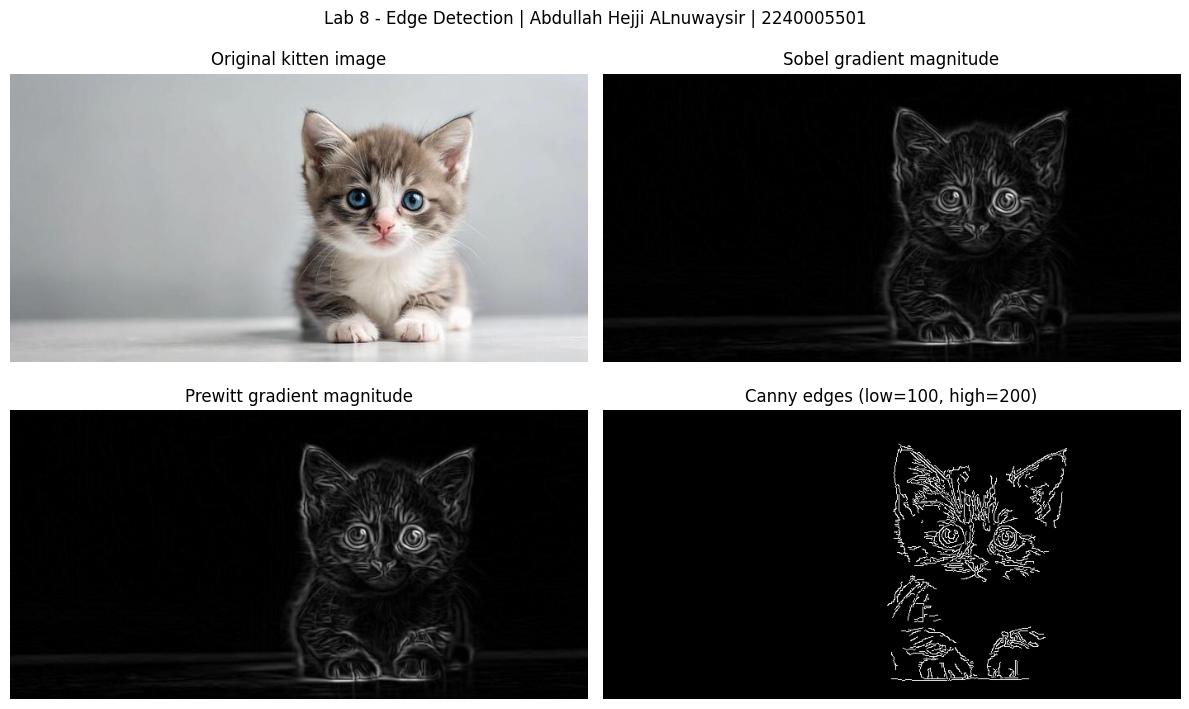

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
panels = [rgb, sobel, prewitt, canny_100_200]
titles = [
    "Original kitten image",
    "Sobel gradient magnitude",
    "Prewitt gradient magnitude",
    "Canny edges (low=100, high=200)",
]

for ax, panel, title in zip(axes.flat, panels, titles):
    if panel.ndim == 3:
        ax.imshow(panel)
    else:
        ax.imshow(panel, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("Lab 8 - Edge Detection | Abdullah Hejji ALnuwaysir | 2240005501", fontsize=12)
fig.tight_layout()
fig.savefig(output_dir / "task1_methods.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

### Task 1: Observations

The Sobel and Prewitt maps show intensity changes around the kitten's ears, eyes, nose, paws, fur markings, and the boundary between the kitten and the background. Their edge responses vary in brightness because the displayed gradient magnitude represents the strength of local intensity changes. The Canny map produces thin, binary edges and keeps prominent boundaries while suppressing some weaker changes at thresholds 100 and 200. Fine fur and whisker details may appear fragmented because they contain small, low-contrast structures.

**Comparison:** Sobel uses weighted derivative kernels, whereas Prewitt uses uniform derivative kernels. Canny applies additional edge-thinning and threshold-based tracking, so its output is a binary map rather than a gradient-magnitude image.

## Task 2: Investigate the Effect of Canny Thresholds

Run Canny with **(30, 90)**, **(50, 150)**, and **(100, 200)**, where each pair is `(low threshold, high threshold)`. The input image and other settings remain unchanged so the experiment isolates the effect of the thresholds.

The high threshold selects strong edge responses. Responses between the low and high thresholds are retained only when connected to strong edges through edge tracking. Increasing the thresholds generally removes weaker edge candidates; the actual number of detected edge pixels is measured below.

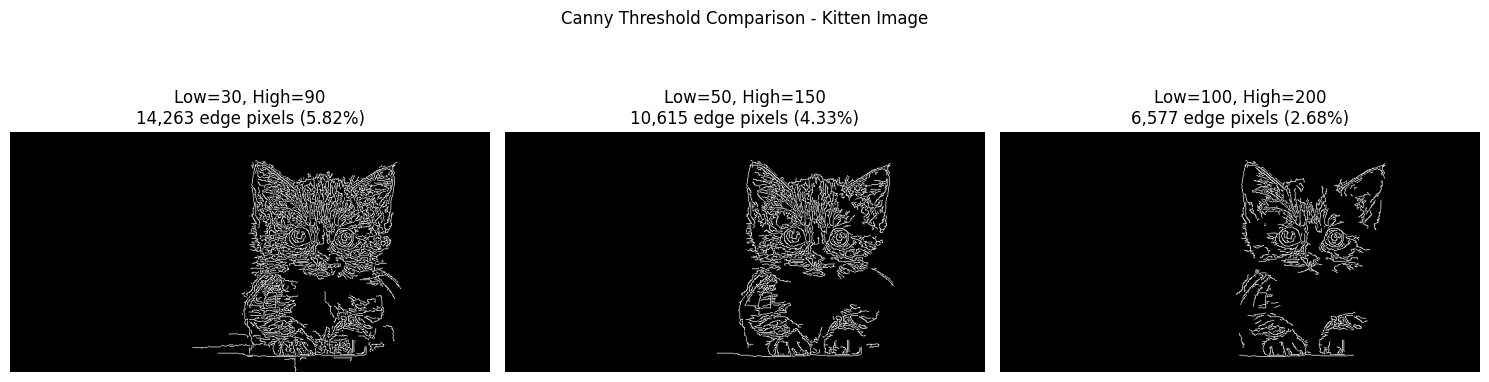

Low | High | Edge pixels | Percentage of image
----|------|-------------|--------------------
 30 |   90 |      14,263 |    5.82%
 50 |  150 |      10,615 |    4.33%
100 |  200 |       6,577 |    2.68%


In [4]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_maps = {}
edge_counts = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
for ax, (low, high) in zip(axes, threshold_pairs):
    # Only thresholds change between runs.
    edges = cv2.Canny(gray, low, high)
    canny_maps[(low, high)] = edges

    count = int(np.count_nonzero(edges))
    percent = 100.0 * count / edges.size
    edge_counts.append((low, high, count, percent))

    ax.imshow(edges, cmap="gray", vmin=0, vmax=255)
    ax.set_title(
        f"Low={low}, High={high}\n{count:,} edge pixels ({percent:.2f}%)"
    )
    ax.axis("off")
    cv2.imwrite(str(output_dir / f"canny_{low}_{high}.png"), edges)

fig.suptitle("Canny Threshold Comparison - Kitten Image", fontsize=12)
fig.tight_layout()
fig.savefig(output_dir / "task2_canny_thresholds.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Low | High | Edge pixels | Percentage of image")
print("----|------|-------------|--------------------")
for low, high, count, percent in edge_counts:
    print(f"{low:3d} | {high:4d} | {count:11,d} | {percent:7.2f}%")

In [5]:
# Display a concise results table in the notebook.
print("Threshold experiment summary")
for low, high, count, percent in edge_counts:
    print(
        f"Thresholds ({low}, {high}): {count:,} edge pixels, "
        f"covering {percent:.2f}% of the image."
    )

Threshold experiment summary
Thresholds (30, 90): 14,263 edge pixels, covering 5.82% of the image.
Thresholds (50, 150): 10,615 edge pixels, covering 4.33% of the image.
Thresholds (100, 200): 6,577 edge pixels, covering 2.68% of the image.


### Task 2: Observations and Conclusion

Compare the three edge maps and the measured edge-pixel counts printed above. Lower thresholds are more sensitive to small intensity changes, so they tend to preserve finer details and texture but can also retain more unwanted edges. Higher thresholds are more selective and usually produce fewer edge pixels, emphasizing stronger boundaries while omitting some subtle details.

The best threshold pair depends on the goal: lower thresholds are useful when retaining detail is important, while higher thresholds can give a cleaner result when weaker texture is distracting. The measured counts in this notebook are specific to the supplied kitten image and OpenCV's Canny implementation.

## Conclusion

Sobel and Prewitt visualize the strength of local intensity gradients; Canny returns a thinner binary edge map using thresholding and edge tracking. The threshold experiment demonstrates the trade-off between retaining fine detail and suppressing weak edges. The input image, individual edge maps, and comparison figures are saved in the `results` folder.